### Make temporary directory

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_KILZQNUHRKFP


### Main

In [3]:
from matplotlib import pyplot as plt
from matplotlib import cm
import numpy as np
import os
from nd2reader import ND2Reader
from microfilm.microplot import microshow
from skimage import exposure, filters

In [4]:
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import os
from nd2reader import ND2Reader
from microfilm.microplot import microshow
from skimage import exposure, filters, transform
from skimage import io
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
with ND2Reader('/bucket/ReiterU/tissue_clearing/20210428_squid_brain_cryosection_immunostain/Acetyl_Tubulin_1-2500_20x_Large_Field.nd2') as images:
    print(images.metadata)
    pixel_mirons = images.metadata["pixel_microns"]

    xs = images.metadata["width"]
    ys = images.metadata["height"]
    raw = np.zeros((2, ys, xs))

    for c in range(2):
        raw[c, :, :] = images.get_frame_2D(c=c)

{'height': 17562, 'width': 21952, 'date': datetime.datetime(2021, 4, 28, 11, 44, 50), 'fields_of_view': [0], 'frames': [0], 'z_levels': [], 'z_coordinates': [-156.35000000000002], 'total_images_per_channel': 1, 'channels': ['GFP-B', 'GFP-B'], 'pixel_microns': 0.325567101193858, 'num_frames': 1, 'experiment': {'description': 'unknown', 'loops': []}, 'events': []}


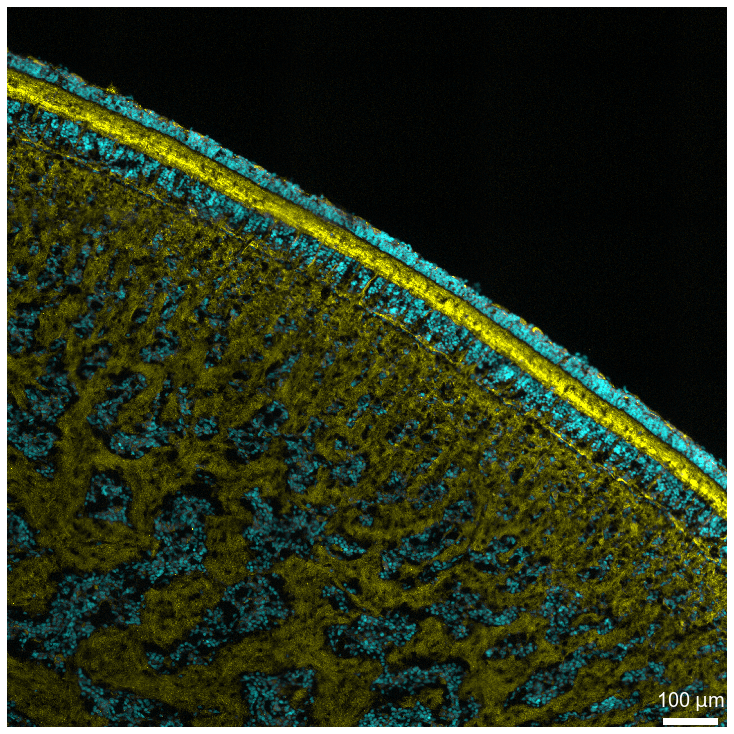

In [7]:
img = raw[:, 2400:6400, 16000:20000].copy()
img[0] = np.clip((img[0] - 100) / (900 - 100), 0, 1)
img[1] = np.clip((img[1] - 100) / (500 - 100), 0, 1)

microim = microshow(
        images=img, fig_scaling=10,
        cmaps=['pure_cyan', 'pure_yellow'], rescale_type="limits", limits=[0,1],
        unit='um', scalebar_size_in_units=100, scalebar_unit_per_pix=pixel_mirons, scalebar_font_size=20, scalebar_thickness=0.01,
        label_text="", label_font_size=20)

microim.savefig(os.path.join(tmpdir, 'squid_OL.jpg'), bbox_inches='tight', pad_inches=0, dpi=300)

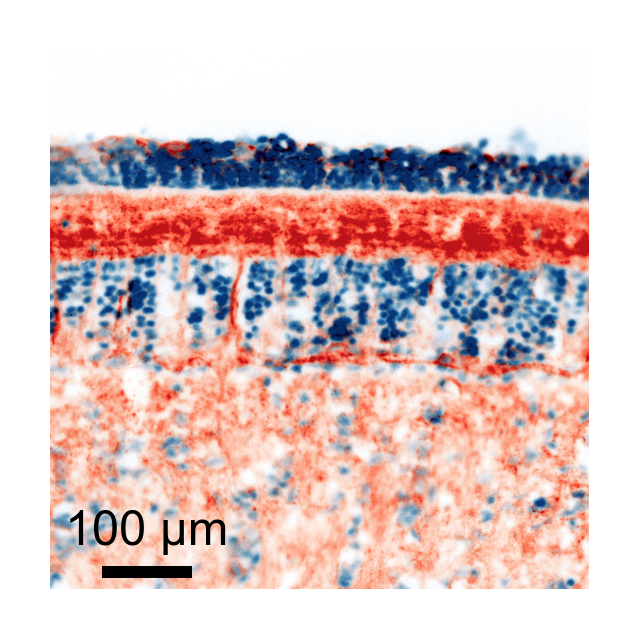

In [14]:
gamma = 1.2
vmax1, vmin1 = 700, 120
vmax2, vmin2 = 450, 120

cropped = raw[:, 3000:5500, 17000:19000]
raw2 = []
for i in range(2):
    raw2.append(transform.rotate(cropped[i], 30, resize=True, preserve_range=True))
raw2 = np.array(raw2)
raw2 = raw2[:, 850:1850, 1000:2000]

img = np.power(raw2, 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

cm1 = plt.get_cmap('Blues')
colors = cm1(np.linspace(0, 0.9, 256))
colors[0] = (1,1,1,1)
interted_cm1 = ListedColormap(1 - colors[:, :3])

cm2 = plt.get_cmap('Reds')
colors = cm2(np.linspace(0.0, 0.8, 256))
colors[0] = (1,1,1,1)
inverted_cm2 = ListedColormap(1 - colors[:, :3])

nuclear_rgb = interted_cm1(nuclear_norm)[..., :3]
tubulin_rgb = inverted_cm2(tubulin_norm)[..., :3]

overlay = nuclear_rgb + tubulin_rgb
# overlay = tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(1.4,1.4), dpi=500)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 100
pixel_size_um = 0.65
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig("OL_deep_retina.pdf", bbox_inches='tight', transparent=True)
plt.show()

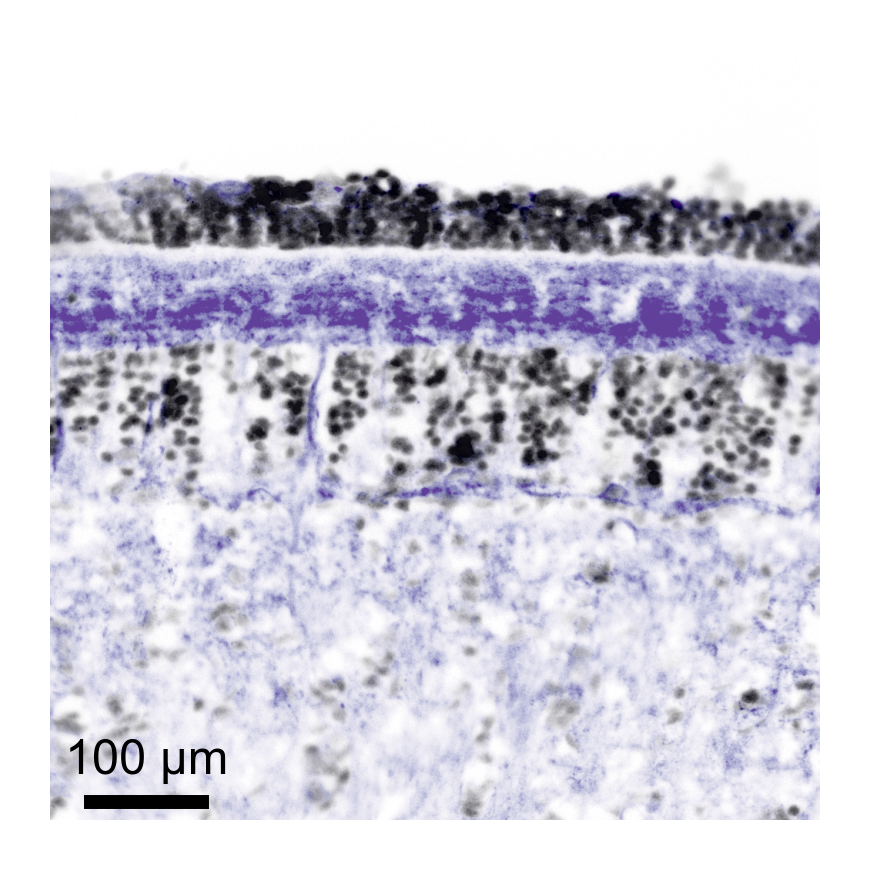

In [10]:
gamma = 1.2
vmax1, vmin1 = 800, 120
vmax2, vmin2 = 450, 120

cropped = raw[:, 3000:5500, 17000:19000]
raw2 = []
for i in range(2):
    raw2.append(transform.rotate(cropped[i], 30, resize=True, preserve_range=True))
raw2 = np.array(raw2)
raw2 = raw2[:, 850:1850, 1000:2000]

img = np.power(raw2, 1/gamma)
nuclear_norm = np.clip((img[0] - np.power(vmin1, 1/gamma)) / (np.power(vmax1, 1/gamma) - np.power(vmin1, 1/gamma)), 0, 1)
tubulin_norm = np.clip((img[1] - np.power(vmin2, 1/gamma)) / (np.power(vmax2, 1/gamma) - np.power(vmin2, 1/gamma)), 0, 1)

cm1 = plt.get_cmap('Greys')
colors = cm1(np.linspace(0, 0.9, 256))
colors[0] = (1,1,1,1)
interted_cm1 = ListedColormap(1 - colors[:, :3])

cm2 = plt.get_cmap('Purples')
colors = cm2(np.linspace(0.0, 0.8, 256))
colors[0] = (1,1,1,1)
inverted_cm2 = ListedColormap(1 - colors[:, :3])

nuclear_rgb = interted_cm1(nuclear_norm)[..., :3]
tubulin_rgb = inverted_cm2(tubulin_norm)[..., :3]

overlay = nuclear_rgb + tubulin_rgb
# overlay = tubulin_rgb
overlay = np.clip(overlay, 0, 1)
inverted = 1 - overlay

# Show
fig, ax = plt.subplots(figsize=(2,2), dpi=500)
ax.imshow(inverted)
ax.axis('off')

# scalebar
real_length_um = 100
pixel_size_um = 0.65
scalebar = AnchoredSizeBar(ax.transData,
                           real_length_um / pixel_size_um,
                           f'{real_length_um} µm',
                           'lower left', pad=0.2, color='black',
                            frameon=False, label_top=True, size_vertical=10)
ax.add_artist(scalebar)
plt.savefig("OL_deep_retina.pdf", bbox_inches='tight', transparent=True)
plt.show()